In [1]:
import torch, whisper
print(torch.__version__, torch.version.cuda, torch.cuda.is_available())


2.5.1+cu121 12.1 True


In [2]:

import whisper
from pyannote.audio import Pipeline

import tempfile
import os

c:\Users\ASUS\miniconda3\envs\meetinganalyzer\lib\site-packages\pytorch_lightning\utilities\imports.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
c:\Users\ASUS\miniconda3\envs\meetinganalyzer\lib\site-packages\pyannote\audio\core\io.py:42: UserWarning: torchaudio._backend.set_audio_backend has been deprecated. With dispatcher enabled, this function is no-op. You can remove the function call.
  torchaudio.set_audio_backend("soundfile")


In [3]:
import torch
print(torch.cuda.is_available())
print(torch.version.cuda)



True
12.1


In [4]:
#Diarrization and Transcript
import torchaudio
import torch
import os


resampled_file = r"C:\Users\ASUS\Downloads\exampleaudioconvert.wav"

print(os.path.exists(resampled_file))

# 1. Load models
whisper_model = whisper.load_model("small")
pipeline = Pipeline.from_pretrained(
    "pyannote/speaker-diarization"
)


# 2. Transcribe whole audio with Whisper
whisper_result = whisper_model.transcribe(resampled_file, word_timestamps=True)

True


c:\Users\ASUS\miniconda3\envs\meetinganalyzer\lib\site-packages\pyannote\audio\pipelines\speaker_verification.py:43: UserWarning: torchaudio._backend.get_audio_backend has been deprecated. With dispatcher enabled, this function is no-op. You can remove the function call.
  backend = torchaudio.get_audio_backend()
The torchaudio backend is switched to 'soundfile'. Note that 'sox_io' is not supported on Windows.
c:\Users\ASUS\miniconda3\envs\meetinganalyzer\lib\site-packages\speechbrain\utils\torch_audio_backend.py:22: UserWarning: torchaudio._backend.set_audio_backend has been deprecated. With dispatcher enabled, this function is no-op. You can remove the function call.
  torchaudio.set_audio_backend("soundfile")
The torchaudio backend is switched to 'soundfile'. Note that 'sox_io' is not supported on Windows.
c:\Users\ASUS\miniconda3\envs\meetinganalyzer\lib\site-packages\pyannote\audio\pipelines\speaker_verification.py:53: UserWarning: torchaudio._backend.set_audio_backend has been de

In [5]:
# 3. Diarize audio
diarization = pipeline(resampled_file)
segments = [(turn.start, turn.end, speaker) for turn, _, speaker in diarization.itertracks(yield_label=True)]

final_transcript = []

for segment in whisper_result["segments"]:
    for word in segment["words"]:
        w_start = word["start"]
        w_end = word["end"]
        text = word["word"]

        speaker = "Unknown"
        max_overlap = 0.0

        for s_start, s_end, s_label in segments:
            overlap = max(0, min(w_end, s_end) - max(w_start, s_start))
            if overlap > max_overlap:
                max_overlap = overlap
                speaker = s_label

        final_transcript.append([speaker, w_start, w_end, text.strip()])
    

In [6]:
merged1 = []

current_speaker = None
current_text = []
start_time = None
end_time = None

for i in range(1,len(final_transcript)):
    if final_transcript[i][0] == "Unknown":
        if final_transcript[i-1][0] == final_transcript[i+1][0]:
            final_transcript[i][0] = final_transcript[i-1][0]


for speaker, w_start, w_end, word in final_transcript:

    if speaker != current_speaker:
        if current_text:
            merged1.append([
                current_speaker,
                start_time,
                end_time,
                " ".join(current_text)
            ])

        current_speaker = speaker
        current_text = [word]
        start_time = w_start
        end_time = w_end
    else:
        current_text.append(word)
        end_time = w_end

# Append last segment
if current_text:
    merged1.append([
        current_speaker,
        start_time,
        end_time,
        " ".join(current_text)
    ])
print(merged1)

[['SPEAKER_03', 0.0, 16.82, "Thanks for coming to today's monthly meeting. Let's start with apologies for absence. Oh and before I forget Frank Lyons is running a bit late, he texted me this morning. And Gary Cope and Karl Madden emailed apologies."], ['SPEAKER_02', 18.12, 27.22, "Anyone else? Joey Ballon, Weasley Cartmay, a kid she's struggling with some personal issues. I think she's got some sort of thought thing that she's got. Okay thank you. Where's Clive?"], ['SPEAKER_03', 28.0, 34.1, "Oh I completely forgot, yes. He can't be here, he's had to go to a meeting elsewhere. Dammit."], ['SPEAKER_01', 34.58, 35.52, 'Oh and Janet Bowers'], ['SPEAKER_00', 35.52, 39.44, "is off sick as well. Oh that's a surprise. To tell you the truth I forgot what she looked like."], ['SPEAKER_03', 39.68, 58.64, "And I'm delighted to announce we have a new team member with us and specialist minute taker. So for the benefit of the new addition to the team shall we all introduce ourselves and what we get 

In [7]:
#handling the unknowns
prev = None


for speaker, start, end, text in merged1:
    print(f"{speaker} [{start:.2f} → {end:.2f}]: {text}")

SPEAKER_03 [0.00 → 16.82]: Thanks for coming to today's monthly meeting. Let's start with apologies for absence. Oh and before I forget Frank Lyons is running a bit late, he texted me this morning. And Gary Cope and Karl Madden emailed apologies.
SPEAKER_02 [18.12 → 27.22]: Anyone else? Joey Ballon, Weasley Cartmay, a kid she's struggling with some personal issues. I think she's got some sort of thought thing that she's got. Okay thank you. Where's Clive?
SPEAKER_03 [28.00 → 34.10]: Oh I completely forgot, yes. He can't be here, he's had to go to a meeting elsewhere. Dammit.
SPEAKER_01 [34.58 → 35.52]: Oh and Janet Bowers
SPEAKER_00 [35.52 → 39.44]: is off sick as well. Oh that's a surprise. To tell you the truth I forgot what she looked like.
SPEAKER_03 [39.68 → 58.64]: And I'm delighted to announce we have a new team member with us and specialist minute taker. So for the benefit of the new addition to the team shall we all introduce ourselves and what we get up to. Yeah okay I'll sta

In [8]:
import re

def split_into_sentences(transcript):
    """
    Split each (speaker, start, end, text) into sentence-level segments.
    Timestamps are distributed proportionally by character length.
    """
    sentence_regex = re.compile(r'(?<=[.!?])\s+')
    output = []

    for speaker, start, end, text in transcript:
        text = text.strip()
        if not text:
            continue

        sentences = sentence_regex.split(text)

        if len(sentences) == 1:
            output.append((speaker, start, end, text))
            continue

        total_chars = sum(len(s) for s in sentences)
        duration = end - start
        current_time = start

        for sentence in sentences:
            sentence = sentence.strip()
            if not sentence:
                continue

            proportion = len(sentence) / total_chars
            sent_duration = proportion * duration
            sent_end = current_time + sent_duration

            output.append((
                speaker,
                round(current_time, 2),
                round(sent_end, 2),
                sentence
            ))

            current_time = sent_end

    return output


In [9]:
def format_time(seconds):
    seconds = float(seconds)
    h = int(seconds // 3600)
    m = int((seconds % 3600) // 60)
    s = seconds % 60

    if h > 0:
        return f"{h:d}:{m:02d}:{s:05.2f}"
    else:
        return f"{m:d}:{s:05.2f}"

final_transcript = split_into_sentences(merged1)
for speaker, start, end, text in final_transcript:
    print(f"{speaker} [{format_time(start)} → {format_time(end)}]: {text}",end="\n")


SPEAKER_03 [0:00.00 → 0:03.50]: Thanks for coming to today's monthly meeting.
SPEAKER_03 [0:03.50 → 0:06.54]: Let's start with apologies for absence.
SPEAKER_03 [0:06.54 → 0:13.08]: Oh and before I forget Frank Lyons is running a bit late, he texted me this morning.
SPEAKER_03 [0:13.08 → 0:16.82]: And Gary Cope and Karl Madden emailed apologies.
SPEAKER_02 [0:18.12 → 0:18.73]: Anyone else?
SPEAKER_02 [0:18.73 → 0:22.72]: Joey Ballon, Weasley Cartmay, a kid she's struggling with some personal issues.
SPEAKER_02 [0:22.72 → 0:25.75]: I think she's got some sort of thought thing that she's got.
SPEAKER_02 [0:25.75 → 0:26.51]: Okay thank you.
SPEAKER_02 [0:26.51 → 0:27.22]: Where's Clive?
SPEAKER_03 [0:28.00 → 0:29.88]: Oh I completely forgot, yes.
SPEAKER_03 [0:29.88 → 0:33.63]: He can't be here, he's had to go to a meeting elsewhere.
SPEAKER_03 [0:33.63 → 0:34.10]: Dammit.
SPEAKER_01 [0:34.58 → 0:35.52]: Oh and Janet Bowers
SPEAKER_00 [0:35.52 → 0:36.36]: is off sick as well.
SPEAKER_00 [

In [16]:


from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Load once (outside function)
sbert_model = SentenceTransformer("all-MiniLM-L6-v2")

def extractive_sbert(sentence_tuples, num_sentences=5):
    """
    sentence_tuples: list of (speaker, start, end, sentence)
    returns: top-ranked sentence tuples
    """
    sentences = [s for _, _, _, s in sentence_tuples]

    embeddings = sbert_model.encode(
        sentences,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    centroid = embeddings.mean(axis=0)

    scores = cosine_similarity([centroid], embeddings)[0]

    # Penalize junk
    for i, sent in enumerate(sentences):
        if not sent.strip().endswith((".", "?", "!")):
            scores[i] *= 0.3
        if len(sent.split()) < 6:
            scores[i] *= 0.5

    top_idx = np.argsort(scores)[-num_sentences:]
    top_idx = sorted(top_idx)

    return [sentence_tuples[i] for i in top_idx]


In [17]:
def is_complete_sentence(sentence):
    sentence = sentence.strip()
    return (
        len(sentence.split()) >= 6 and
        sentence[-1] in ".?!"
    )

def is_valid_sentence(sentence):
    bad_patterns = [
        "we've got used to the",
        "you know ever since",
        "sort of",
        "kind of",
    ]

    if any(p in sentence.lower() for p in bad_patterns):
        return False

    return True


In [22]:
clean_sentences = [
    (s, st, et, sent)
    for s, st, et, sent in final_transcript
    if is_complete_sentence(sent) and is_valid_sentence(sent)
]

important_sentences = extractive_sbert(
    clean_sentences,
    num_sentences=5
)

for speaker, start, end, text in important_sentences:
    print(f"{speaker} [{format_time(start)} → {format_time(end)}]: {text}")

SPEAKER_03 [2:13.85 → 2:17.09]: I'm sorry are you saying there is a problem with car parking Lucy?
SPEAKER_03 [2:43.37 → 2:47.56]: Okay it's okay we're just discussing car parking issues.
SPEAKER_01 [2:57.37 → 3:00.44]: Okay I mentioned priority parking so we need to make a decision on this.
SPEAKER_03 [3:16.20 → 3:18.97]: I think priority parking is a good idea Julian.
SPEAKER_03 [4:00.04 → 4:10.00]: As it's a difficult area to park with a two -hour restriction and client meetings are always running over that would leave us with two spaces left to be allocated.


In [23]:
def chunk_sentences(sentence_tuples, sentences_per_chunk=6):
    """
    Groups sentence tuples into batches for abstractive summarization.
    """
    chunks = []
    current = []

    for tup in sentence_tuples:
        current.append(tup)

        if len(current) >= sentences_per_chunk:
            chunks.append(current)
            current = []

    if current:
        chunks.append(current)

    return chunks

def sentences_to_text(sentence_chunk):
    return " ".join(sentence for _, _, _, sentence in sentence_chunk)


In [ ]:
from transformers import pipeline

summarizer = pipeline(
    "summarization",
    model="t5-base",
    device=0
)


def abstractive_summary(text):
    prompt = (
        "summarize the meeting, including key decisions, "
        "introductions, and issues discussed:\n\n"
    )
    return summarizer(
        prompt + text,
        max_new_tokens=180,
        min_new_tokens=100,
        do_sample=False,
        num_beams=4,
        repetition_penalty=1.2,
        truncation=True
    )[0]["summary_text"]

extractive_text = " ".join(
    sentence for _, _, _, sentence in important_sentences
)

final_summary = abstractive_summary(extractive_text)


Device set to use cuda:0
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.
Your max_length is set to 200, but your input_length is only 113. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=56)


I'm sorry are you saying there is a problem with car parking Lucy? Okay it's okay we're just discussing car parking issues. Okay I mentioned priority parking so we need to make a decision on this. I think priority parking is a good idea Julian. As it's a difficult area to park with a two -hour restriction and client meetings are always running over that would leave us with two spaces left to be allocated.
it's a difficult area to park with a two -hour restriction and client meetings are always running over that would leave us with two spaces left to be allocated . we're just discussing car parking issues, including key decisions, introductions, and issues discussed . the meeting will take place on thursday, november 8 at st james' park in london, scotland, britain .


In [ ]:
import re

def detect_action_items_rule(sentences):
    patterns = [
        r"\bwill\b", r"\bneed to\b", r"\bshould\b", r"\bmust\b",
        r"\bplease\b", r"\bplan to\b", r"\bfollow up\b", r"\bdeadline\b"
    ]

    action_verbs = [
        "send", "email", "share", "decide", "schedule",
        "review", "assign", "prepare", "update"
    ]

    hedges = ["think", "maybe", "might", "could", "discuss", "consider"]

    action_items = []

    for s in sentences:
        s_lower = s.lower()

        if any(h in s_lower for h in hedges):
            continue

        has_modal = any(re.search(p, s_lower) for p in patterns)
        has_action = any(v in s_lower for v in action_verbs)

        if has_modal and has_action:
            action_items.append(s)

    return action_items


# Example usage
sentences = [t[3] for t in final_transcript]

action_items = detect_action_items_rule(sentences)

for a in action_items:
    print("-", a)


- Yeah well there's been an actual problem with car parking you know ever since George Hiddon Shipman moved into the new officers of the back and we knew this was going to happen eventually but you know our stuff I've got used to the extra spaces and what's happened there's been a few arguments there was a really bad one where one of our lot come play to one of our lot which is really bad because we're trying to like it's just started with a bad reputation so what we need to do is let one of you know all of know that the spaces belong to them actually.
- We need to send an email letting all the staff know there are only five spaces that belong to us.
- Well I think we should think about priority parking as well it's the only way we're going to stop people rowing on a regular basis.
- Please can we get back?
- Okay I mentioned priority parking so we need to make a decision on this.
- You know I think that anyone that needs their car for work and uses it during work hours should be given


=== Analytics ===


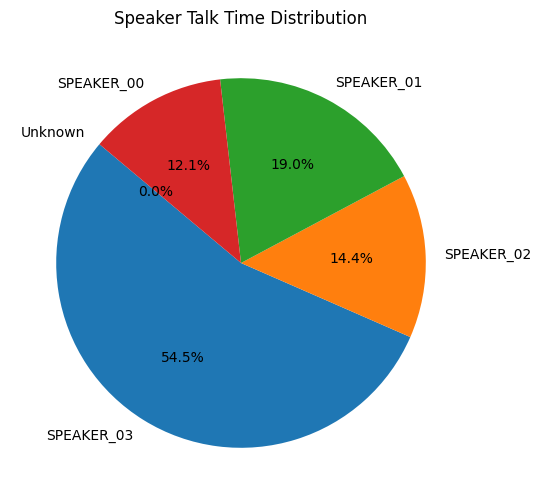

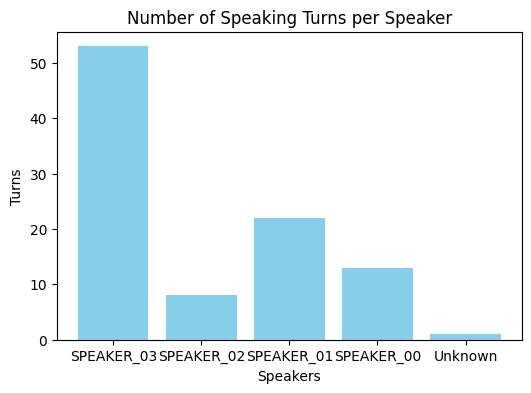

In [35]:
import matplotlib.pyplot as plt
from collections import defaultdict, Counter

# === Talk Time per Speaker ===
def plot_talk_time(speaker_transcripts):
    talk_time = defaultdict(float)
    for spk, start, end, _ in speaker_transcripts:
        talk_time[spk] += (end - start)

    labels = list(talk_time.keys())
    sizes = list(talk_time.values())

    plt.figure(figsize=(6,6))
    plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140)
    plt.title("Speaker Talk Time Distribution")
    plt.show()

# === Number of Turns per Speaker ===
def plot_speaker_turns(speaker_transcripts):
    turns = Counter([spk for spk, _, _, _ in speaker_transcripts])
    plt.figure(figsize=(6,4))
    plt.bar(turns.keys(), turns.values(), color="skyblue")
    plt.title("Number of Speaking Turns per Speaker")
    plt.xlabel("Speakers")
    plt.ylabel("Turns")
    plt.show()



# === Run Analytics ===
print("\n=== Analytics ===")

# Talk Time
plot_talk_time(final_transcript)

# Turns
plot_speaker_turns(final_transcript)
